In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv('/content/Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [4]:
for i in df.columns:
  print(f'---------------------------------{i}---------------------------------')
  print (df[i].value_counts())

---------------------------------customerID---------------------------------
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64
---------------------------------gender---------------------------------
gender
Male      3555
Female    3488
Name: count, dtype: int64
---------------------------------SeniorCitizen---------------------------------
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
---------------------------------Partner---------------------------------
Partner
No     3641
Yes    3402
Name: count, dtype: int64
---------------------------------Dependents---------------------------------
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
---------------------------------tenure---------------------------------
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57


In [5]:
df.shape

(7043, 21)

In [6]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [7]:
df.drop(columns=['customerID'], inplace=True)

In [8]:
for i in df.columns:
  print(f'---------------------------------{i}---------------------------------')
  print (df[i].unique())

---------------------------------gender---------------------------------
['Female' 'Male']
---------------------------------SeniorCitizen---------------------------------
[0 1]
---------------------------------Partner---------------------------------
['Yes' 'No']
---------------------------------Dependents---------------------------------
['No' 'Yes']
---------------------------------tenure---------------------------------
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
---------------------------------PhoneService---------------------------------
['No' 'Yes']
---------------------------------MultipleLines---------------------------------
['No phone service' 'No' 'Yes']
---------------------------------InternetService---------------------------------
['DSL' 'Fiber optic' 'No']
---------------------------------Onl

In [9]:
# label encoding Gender
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})

In [10]:
df['gender'].unique()

array([0, 1])

In [11]:
# label encoding partners and dependents
df['Partner'] = df['Partner'].map({'Yes': 1, 'No': 0})
df['Dependents'] = df['Dependents'].map({'Yes': 1, 'No': 0})

In [12]:
df['Partner'].unique()

array([1, 0])

In [13]:
df['Dependents'].unique()

array([0, 1])

In [14]:
# label encoding phone service
df['PhoneService'] = df['PhoneService'].map({'Yes': 1, 'No': 0})

In [15]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [16]:
df['PaperlessBilling'] = df['PaperlessBilling'].map({'Yes': 1, 'No': 0})

In [17]:
for i in df.columns:
  print(f'---------------------------------{i}---------------------------------')
  print (df[i].unique())

---------------------------------gender---------------------------------
[0 1]
---------------------------------SeniorCitizen---------------------------------
[0 1]
---------------------------------Partner---------------------------------
[1 0]
---------------------------------Dependents---------------------------------
[0 1]
---------------------------------tenure---------------------------------
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
---------------------------------PhoneService---------------------------------
[0 1]
---------------------------------MultipleLines---------------------------------
['No phone service' 'No' 'Yes']
---------------------------------InternetService---------------------------------
['DSL' 'Fiber optic' 'No']
---------------------------------OnlineSecurity----------------------

In [18]:
# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check data types
print(df.dtypes)

gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling      int64
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


In [19]:
df.isnull().sum().sort_values(ascending=False)

,0
TotalCharges,11
gender,0
Partner,0
SeniorCitizen,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0
OnlineBackup,0


In [20]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

,0
TotalCharges,0.156183
gender,0.000000
Partner,0.000000
SeniorCitizen,0.000000
Dependents,0.000000
tenure,0.000000
MultipleLines,0.000000
PhoneService,0.000000
OnlineSecurity,0.000000
OnlineBackup,0.000000


In [21]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [22]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

,0
gender,0.0
SeniorCitizen,0.0
Partner,0.0
Dependents,0.0
tenure,0.0
PhoneService,0.0
MultipleLines,0.0
InternetService,0.0
OnlineSecurity,0.0
OnlineBackup,0.0


In [23]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 22


In [24]:
df = df.drop_duplicates()

In [25]:
categorical_cols = [
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaymentMethod'
]

df = pd.get_dummies(
    df,
    columns=categorical_cols,
    dtype=int
)

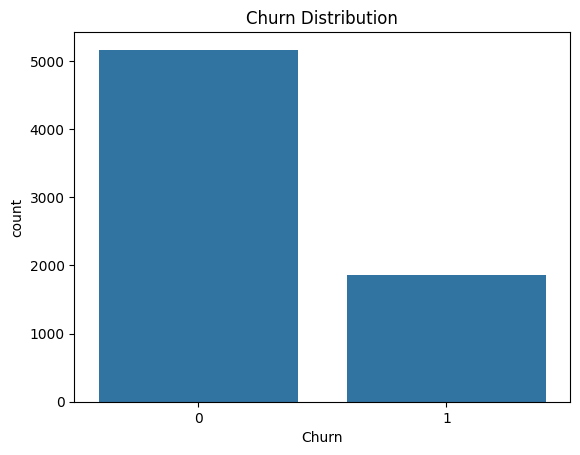

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Churn')
plt.title('Churn Distribution')
plt.show()

In [27]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'MultipleLines_No', 'MultipleLines_No phone service',
       'MultipleLines_Yes', 'InternetService_DSL',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No', 'OnlineSecurity_No internet service',
       'OnlineSecurity_Yes', 'OnlineBackup_No',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No', 'DeviceProtection_No internet service',
       'DeviceProtection_Yes', 'TechSupport_No',
       'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMetho

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 41 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   7021 non-null   int64  
 1   SeniorCitizen                            7021 non-null   int64  
 2   Partner                                  7021 non-null   int64  
 3   Dependents                               7021 non-null   int64  
 4   tenure                                   7021 non-null   int64  
 5   PhoneService                             7021 non-null   int64  
 6   PaperlessBilling                         7021 non-null   int64  
 7   MonthlyCharges                           7021 non-null   float64
 8   TotalCharges                             7021 non-null   float64
 9   Churn                                    7021 non-null   int64  
 10  MultipleLines_No                         7021 non-nul

In [29]:
for i in df.columns:
  print(f'---------------------------------{i}---------------------------------')
  print (df[i].unique())

---------------------------------gender---------------------------------
[0 1]
---------------------------------SeniorCitizen---------------------------------
[0 1]
---------------------------------Partner---------------------------------
[1 0]
---------------------------------Dependents---------------------------------
[0 1]
---------------------------------tenure---------------------------------
[ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
---------------------------------PhoneService---------------------------------
[0 1]
---------------------------------PaperlessBilling---------------------------------
[1 0]
---------------------------------MonthlyCharges---------------------------------
[29.85 56.95 53.85 ... 63.1  44.2  78.7 ]
---------------------------------TotalCharges---------------------------------

In [31]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'], errors='ignore')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [32]:
X

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,1,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,1,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,84.80,1990.50,0,...,0,0,1,0,1,0,0,0,0,1
7039,0,0,1,1,72,1,1,103.20,7362.90,0,...,0,0,1,0,1,0,0,1,0,0
7040,0,0,1,1,11,0,1,29.60,346.45,0,...,1,0,0,1,0,0,0,0,1,0
7041,1,1,1,0,4,1,1,74.40,306.60,0,...,1,0,0,1,0,0,0,0,0,1


In [34]:
X.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'MultipleLines_No', 'MultipleLines_No phone service',
       'MultipleLines_Yes', 'InternetService_DSL',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No', 'OnlineSecurity_No internet service',
       'OnlineSecurity_Yes', 'OnlineBackup_No',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No', 'DeviceProtection_No internet service',
       'DeviceProtection_Yes', 'TechSupport_No',
       'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit 

In [33]:
y

,Churn
0,0
1,0
2,1
3,0
4,1
...,...
7038,0
7039,0
7040,0
7041,1


In [35]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [36]:
numeric_cols = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

lr_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols)
    ],
    remainder='passthrough'
)

lr_pipeline = Pipeline([
    ('preprocessor', lr_preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [39]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(
        random_state=42
    ))
])

In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [41]:
pipelines = {
    'Logistic Regression': lr_pipeline,
    'Decision Tree': dt_pipeline,
    'Random Forest': rf_pipeline
}

for name, pipeline in pipelines.items():

    pipeline.fit(X_train, y_train)

    print(f'{name} trained successfully!')

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, pipeline in pipelines.items():

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.8028,0.6610,0.5242,0.5847,0.8403
1,Decision Tree,0.7096,0.4550,0.4892,0.4715,0.6402
2,Random Forest,0.7772,0.6057,0.4543,0.5192,0.8171


In [43]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

In [44]:
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

In [45]:
import pandas as pd
from sklearn.model_selection import cross_validate

cv_results = {}

for name, pipeline in pipelines.items():

    print(f"\nRunning Cross Validation: {name}")

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    cv_results[name] = scores

    print(f"{name} completed successfully!")


Running Cross Validation: Logistic Regression
Logistic Regression completed successfully!

Running Cross Validation: Decision Tree
Decision Tree completed successfully!

Running Cross Validation: Random Forest
Random Forest completed successfully!


In [46]:
fold_results = []

for name, scores in cv_results.items():

    for i in range(len(scores['test_accuracy'])):

        fold_results.append({
            'Model': name,
            'Fold': i + 1,

            'Train Accuracy': scores['train_accuracy'][i],
            'Validation Accuracy': scores['test_accuracy'][i],

            'Train F1': scores['train_f1'][i],
            'Validation F1': scores['test_f1'][i],

            'Precision': scores['test_precision'][i],
            'Recall': scores['test_recall'][i],
            'ROC-AUC': scores['test_roc_auc'][i],

            'Fit Time': scores['fit_time'][i],
            'Score Time': scores['score_time'][i]
        })

fold_df = pd.DataFrame(fold_results)

display(fold_df.round(4))

,Model,Fold,Train Accuracy,Validation Accuracy,Train F1,Validation F1,Precision,Recall,ROC-AUC,Fit Time,Score Time
0,Logistic Regression,1,0.8039,0.8149,0.5975,0.6176,0.6802,0.5657,0.8661,0.0876,0.0362
1,Logistic Regression,2,0.8059,0.8068,0.6026,0.6004,0.6626,0.5488,0.8345,0.1021,0.0789
2,Logistic Regression,3,0.8070,0.7952,0.6072,0.5677,0.6426,0.5084,0.8422,0.0578,0.0352
3,Logistic Regression,4,0.8037,0.8157,0.5976,0.6257,0.6758,0.5825,0.8614,0.0725,0.0521
4,Logistic Regression,5,0.8093,0.7836,0.6110,0.5637,0.6038,0.5286,0.8251,0.0505,0.0731
5,Logistic Regression,6,0.8063,0.8087,0.5994,0.6084,0.6627,0.5623,0.8534,0.0598,0.0373
6,Logistic Regression,7,0.8035,0.8085,0.5951,0.6098,0.6614,0.5657,0.8512,0.2126,0.0459
7,Logistic Regression,8,0.8048,0.8183,0.5983,0.6277,0.6853,0.5791,0.8535,0.1910,0.0704
8,Logistic Regression,9,0.8106,0.7916,0.6123,0.5568,0.6364,0.4949,0.8379,0.0575,0.0393
9,Logistic Regression,10,0.8115,0.7854,0.6145,0.5719,0.6053,0.5421,0.8318,0.0699,0.0740


In [52]:
fold_df

,Model,Fold,Train Accuracy,Validation Accuracy,Train F1,Validation F1,Precision,Recall,ROC-AUC,Fit Time,Score Time
0,Logistic Regression,1,0.803874,0.814947,0.597533,0.617647,0.680162,0.565657,0.866110,0.087642,0.036232
1,Logistic Regression,2,0.805920,0.806768,0.602552,0.600368,0.662602,0.548822,0.834497,0.102071,0.078942
2,Logistic Regression,3,0.807033,0.795191,0.607159,0.567669,0.642553,0.508418,0.842175,0.057766,0.035191
3,Logistic Regression,4,0.803695,0.815672,0.597628,0.625678,0.675781,0.582492,0.861378,0.072516,0.052087
4,Logistic Regression,5,0.809259,0.783615,0.610985,0.563734,0.603846,0.528620,0.825126,0.050503,0.073076
5,Logistic Regression,6,0.806322,0.808719,0.599448,0.608379,0.662698,0.562290,0.853372,0.059788,0.037345
6,Logistic Regression,7,0.803472,0.808549,0.595140,0.609800,0.661417,0.565657,0.851198,0.212572,0.045928
7,Logistic Regression,8,0.804807,0.818344,0.598259,0.627737,0.685259,0.579125,0.853527,0.190955,0.070420
8,Logistic Regression,9,0.810594,0.791630,0.612301,0.556818,0.636364,0.494949,0.837942,0.057514,0.039294
9,Logistic Regression,10,0.811485,0.785396,0.614474,0.571936,0.605263,0.542088,0.831760,0.069937,0.074044


In [47]:
summary_results = []

for name, scores in cv_results.items():

    summary_results.append({
        'Model': name,

        'Accuracy Mean': scores['test_accuracy'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),

        'Precision Mean': scores['test_precision'].mean(),
        'Precision Std': scores['test_precision'].std(),

        'Recall Mean': scores['test_recall'].mean(),
        'Recall Std': scores['test_recall'].std(),

        'F1 Mean': scores['test_f1'].mean(),
        'F1 Std': scores['test_f1'].std(),

        'ROC-AUC Mean': scores['test_roc_auc'].mean(),
        'ROC-AUC Std': scores['test_roc_auc'].std(),

        'Average Fit Time': scores['fit_time'].mean(),
        'Average Score Time': scores['score_time'].mean()
    })

summary_df = pd.DataFrame(summary_results)

display(summary_df.round(4))

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,Average Fit Time,Average Score Time
0,Logistic Regression,0.8029,0.0109,0.6516,0.0251,0.5484,0.0235,0.5954,0.0225,0.8455,0.0121,0.0982,0.0557
1,Decision Tree,0.7262,0.0132,0.4834,0.0235,0.5015,0.0255,0.4920,0.0216,0.6553,0.0149,0.1171,0.0378
2,Random Forest,0.7886,0.0094,0.6314,0.0249,0.4835,0.0199,0.5474,0.0193,0.8234,0.0130,2.6461,0.3769


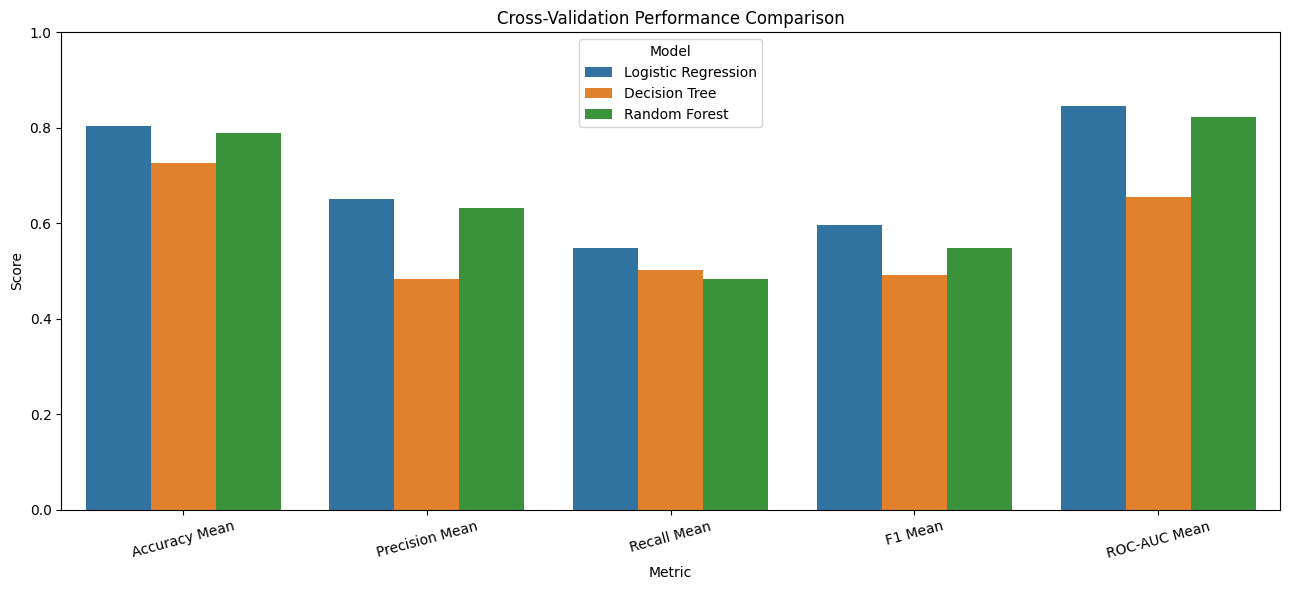

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    'Accuracy Mean',
    'Precision Mean',
    'Recall Mean',
    'F1 Mean',
    'ROC-AUC Mean'
]

plot_df = summary_df.melt(
    id_vars='Model',
    value_vars=metrics,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_df,
    x='Metric',
    y='Score',
    hue='Model'
)

plt.title('Cross-Validation Performance Comparison')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

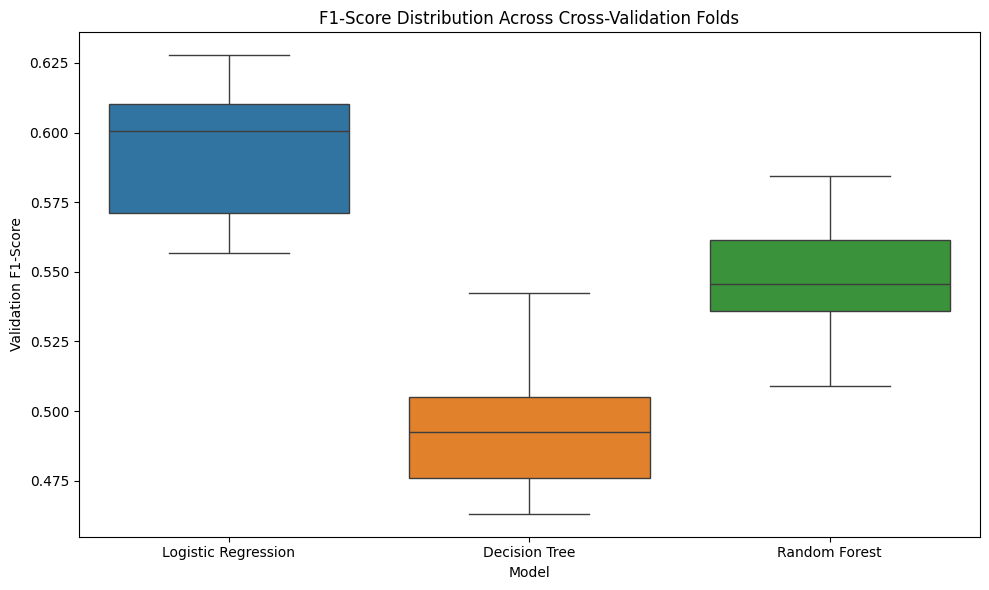

In [49]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=fold_df,
    x='Model',
    y='Validation F1',
    hue='Model',
    legend=False
)

plt.title('F1-Score Distribution Across Cross-Validation Folds')
plt.ylabel('Validation F1-Score')
plt.xlabel('Model')
plt.tight_layout()
plt.show()

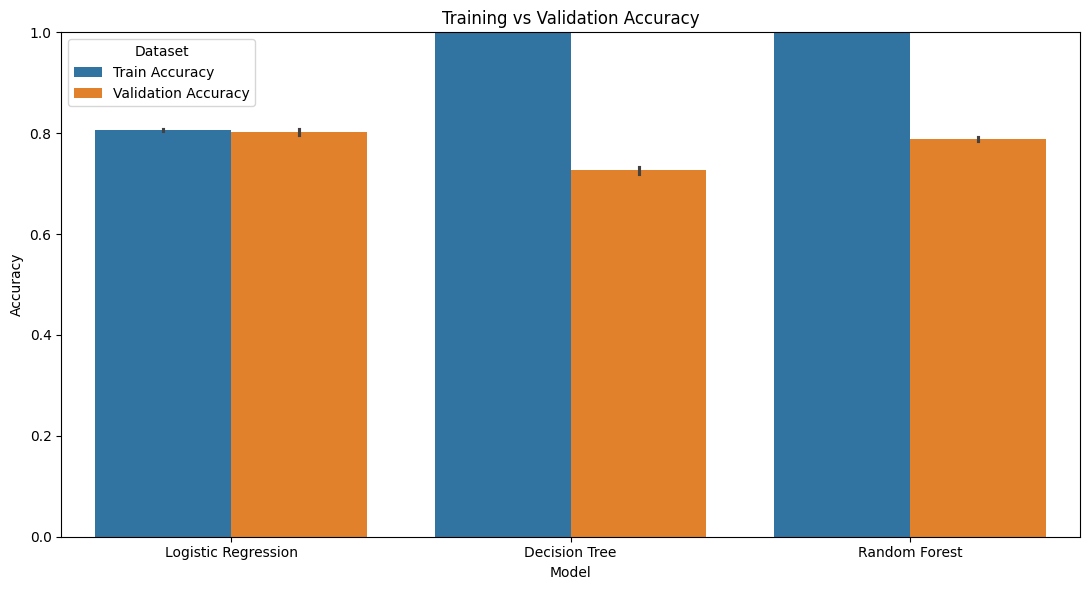

In [50]:
overfit_df = fold_df.melt(
    id_vars=['Model', 'Fold'],
    value_vars=['Train Accuracy', 'Validation Accuracy'],
    var_name='Dataset',
    value_name='Accuracy'
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=overfit_df,
    x='Model',
    y='Accuracy',
    hue='Dataset'
)

plt.title('Training vs Validation Accuracy')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [51]:
ranking = summary_df.sort_values(
    by=['F1 Mean', 'ROC-AUC Mean'],
    ascending=False
)

display(
    ranking[
        ['Model', 'Accuracy Mean', 'Precision Mean',
         'Recall Mean', 'F1 Mean', 'ROC-AUC Mean']
    ].round(4)
)

,Model,Accuracy Mean,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean
0,Logistic Regression,0.8029,0.6516,0.5484,0.5954,0.8455
2,Random Forest,0.7886,0.6314,0.4835,0.5474,0.8234
1,Decision Tree,0.7262,0.4834,0.5015,0.4920,0.6553


In [53]:
for name, pipeline in pipelines.items():

    print(f"Training final {name}...")

    pipeline.fit(X_train, y_train)

    print(f"{name} trained successfully!")

Training final Logistic Regression...
Logistic Regression trained successfully!
Training final Decision Tree...
Decision Tree trained successfully!
Training final Random Forest...
Random Forest trained successfully!


In [54]:
import os
import joblib

os.makedirs('artifacts', exist_ok=True)

model_files = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'Random Forest': 'random_forest.joblib'
}

for name, pipeline in pipelines.items():

    file_path = os.path.join(
        'artifacts',
        model_files[name]
    )

    joblib.dump(pipeline, file_path)

    print(f"Saved {name} -> {file_path}")

Saved Logistic Regression -> artifacts/logistic_regression.joblib
Saved Decision Tree -> artifacts/decision_tree.joblib
Saved Random Forest -> artifacts/random_forest.joblib


In [55]:
metadata = {
    'feature_columns': list(X_train.columns),
    'numeric_columns': numeric_cols,
    'target_name': 'Churn'
}

joblib.dump(
    metadata,
    'artifacts/model_metadata.joblib'
)

['artifacts/model_metadata.joblib']

In [58]:
!pip install scipy joblib seaborn

In [59]:
X_reference = X_train.copy()

# Temporary drift experiment
X_current = X_test.copy()

# Make sure both datasets have identical columns
X_current = X_current.reindex(
    columns=X_reference.columns
)

In [60]:
import numpy as np
import pandas as pd

from scipy.stats import ks_2samp, chi2_contingency


def calculate_psi(reference, current, bins=10):

    reference = pd.Series(reference).dropna().values
    current = pd.Series(current).dropna().values

    if len(reference) == 0 or len(current) == 0:
        return np.nan

    # Create bins using reference distribution
    if len(np.unique(reference)) <= 2:
        edges = np.array([-np.inf, 0.5, np.inf])
    else:
        edges = np.unique(
            np.quantile(reference, np.linspace(0, 1, bins + 1))
        )

        edges[0] = -np.inf
        edges[-1] = np.inf

    ref_counts = np.histogram(reference, bins=edges)[0]
    cur_counts = np.histogram(current, bins=edges)[0]

    # Convert counts into proportions
    ref_pct = ref_counts / len(reference)
    cur_pct = cur_counts / len(current)

    # Avoid division by zero
    epsilon = 0.0001

    ref_pct = np.clip(ref_pct, epsilon, None)
    cur_pct = np.clip(cur_pct, epsilon, None)

    psi = np.sum(
        (cur_pct - ref_pct) *
        np.log(cur_pct / ref_pct)
    )

    return psi

In [61]:
def detect_feature_drift(reference, current):

    results = []

    for col in reference.columns:

        ref = reference[col].dropna()
        cur = current[col].dropna()

        # Determine whether the feature is binary
        is_binary = (
            len(set(ref.unique()).union(set(cur.unique()))) <= 2
        )

        if is_binary:

            categories = sorted(
                set(ref.unique()).union(set(cur.unique()))
            )

            ref_counts = [
                (ref == category).sum()
                for category in categories
            ]

            cur_counts = [
                (cur == category).sum()
                for category in categories
            ]

            _, p_value, _, _ = chi2_contingency(
                [ref_counts, cur_counts]
            )

            test = 'Chi-Square'

        else:

            _, p_value = ks_2samp(ref, cur)

            test = 'KS Test'

        psi = calculate_psi(ref, cur)

        results.append({
            'Feature': col,
            'Test': test,
            'P-Value': p_value,
            'PSI': psi,
            'Reference Mean': ref.mean(),
            'Current Mean': cur.mean(),
            'Drift Detected': p_value < 0.05
        })

    return pd.DataFrame(results).sort_values(
        by='PSI',
        ascending=False
    )

In [62]:
feature_drift = detect_feature_drift(
    X_reference,
    X_current
)

display(feature_drift.round(4))

,Feature,Test,P-Value,PSI,Reference Mean,Current Mean,Drift Detected
7,MonthlyCharges,KS Test,0.8417,0.0066,64.8947,64.6806,False
8,TotalCharges,KS Test,0.3694,0.0055,2290.3233,2272.5421,False
6,PaperlessBilling,Chi-Square,0.0281,0.0044,0.5992,0.5665,True
4,tenure,KS Test,0.9835,0.0030,32.4332,32.6142,False
10,MultipleLines_No phone service,Chi-Square,0.1302,0.0021,0.0944,0.1082,False
5,PhoneService,Chi-Square,0.1302,0.0021,0.9056,0.8918,False
0,gender,Chi-Square,0.1374,0.0020,0.4998,0.5224,False
18,OnlineBackup_No,Chi-Square,0.1830,0.0016,0.4347,0.4548,False
38,PaymentMethod_Electronic check,Chi-Square,0.2672,0.0012,0.3392,0.3231,False
20,OnlineBackup_Yes,Chi-Square,0.2704,0.0012,0.3492,0.3331,False


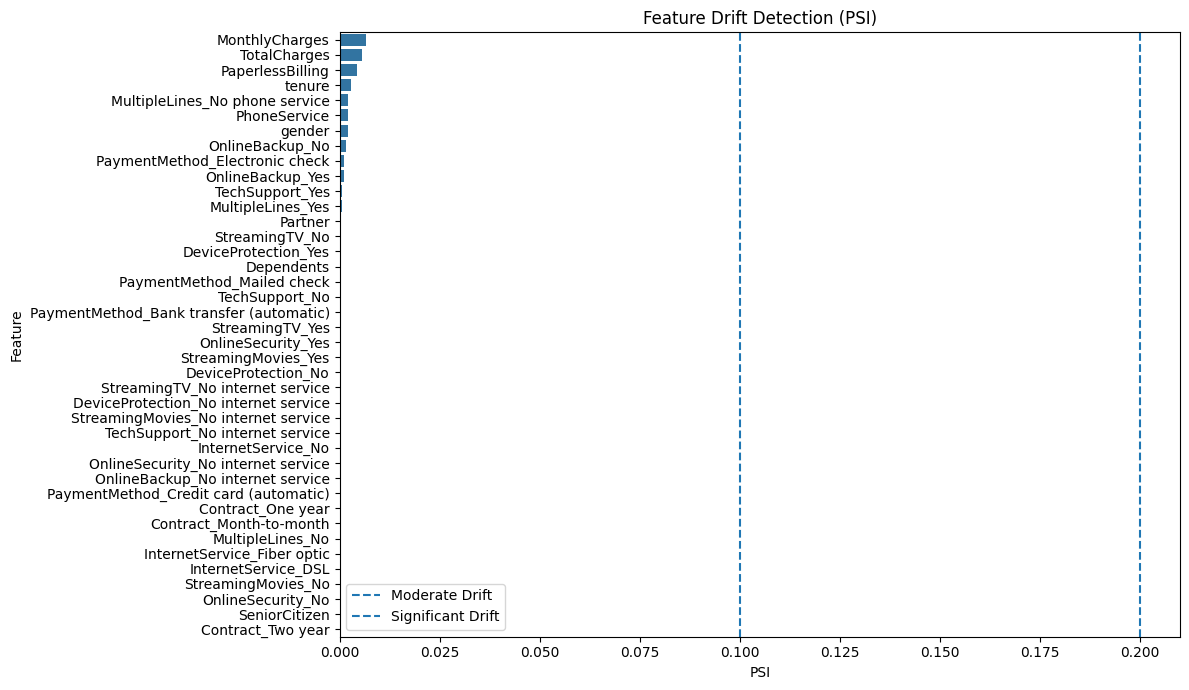

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.barplot(
    data=feature_drift,
    x='PSI',
    y='Feature'
)

plt.axvline(
    0.10,
    linestyle='--',
    label='Moderate Drift'
)

plt.axvline(
    0.20,
    linestyle='--',
    label='Significant Drift'
)

plt.title('Feature Drift Detection (PSI)')
plt.legend()
plt.tight_layout()
plt.show()

In [64]:
from scipy.stats import ks_2samp


def detect_prediction_drift(
    model,
    reference,
    current
):

    ref_prob = model.predict_proba(reference)[:, 1]
    cur_prob = model.predict_proba(current)[:, 1]

    ref_pred = model.predict(reference)
    cur_pred = model.predict(current)

    _, p_value = ks_2samp(ref_prob, cur_prob)

    return {
        'Reference Churn Rate': np.mean(ref_pred),
        'Current Churn Rate': np.mean(cur_pred),

        'Reference Non-Churn Rate': 1 - np.mean(ref_pred),
        'Current Non-Churn Rate': 1 - np.mean(cur_pred),

        'Reference Avg Probability': np.mean(ref_prob),
        'Current Avg Probability': np.mean(cur_prob),

        'Probability KS P-Value': p_value,
        'Prediction Drift': p_value < 0.05
    }

In [65]:
prediction_results = []

for name, model in pipelines.items():

    result = detect_prediction_drift(
        model,
        X_reference,
        X_current
    )

    result['Model'] = name

    prediction_results.append(result)

prediction_drift = pd.DataFrame(prediction_results)

display(prediction_drift.round(4))

,Reference Churn Rate,Current Churn Rate,Reference Non-Churn Rate,Current Non-Churn Rate,Reference Avg Probability,Current Avg Probability,Probability KS P-Value,Prediction Drift,Model
0,0.2208,0.2100,0.7792,0.7900,0.2645,0.2613,0.8913,False,Logistic Regression
1,0.2621,0.2847,0.7379,0.7153,0.2644,0.2851,0.6050,False,Decision Tree
2,0.2650,0.1986,0.7350,0.8014,0.2668,0.2664,0.0000,True,Random Forest


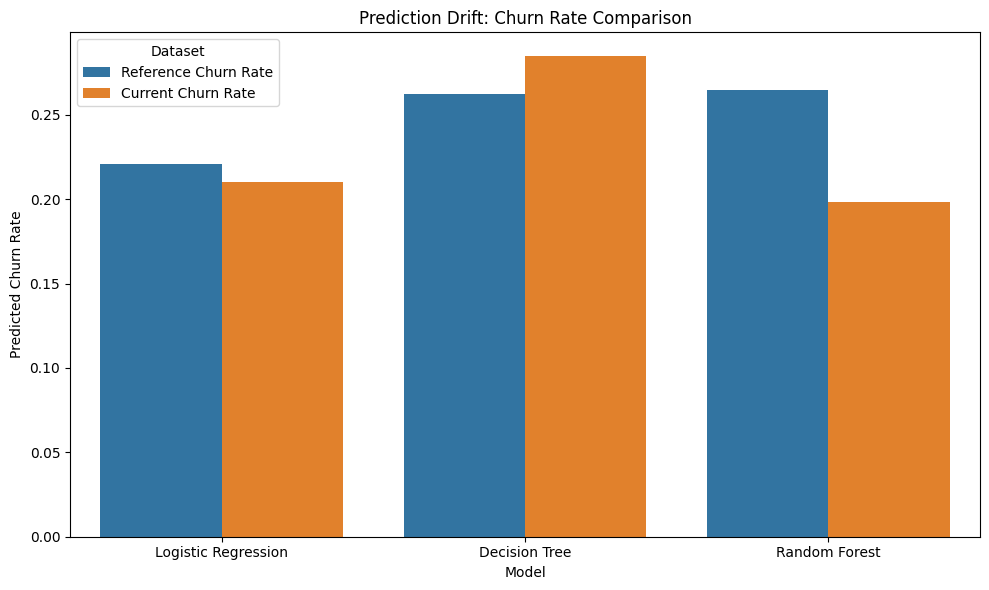

In [66]:
prediction_plot = prediction_drift.melt(
    id_vars='Model',
    value_vars=[
        'Reference Churn Rate',
        'Current Churn Rate'
    ],
    var_name='Dataset',
    value_name='Churn Rate'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=prediction_plot,
    x='Model',
    y='Churn Rate',
    hue='Dataset'
)

plt.title('Prediction Drift: Churn Rate Comparison')
plt.ylabel('Predicted Churn Rate')
plt.tight_layout()
plt.show()

In [67]:
# Actual churn labels for newly collected customers
y_current = ...  # Replace with actual 0/1 labels

In [71]:
X_current = X_test.copy()
y_current = y_test.copy()

In [72]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


def evaluate_model_drift(
    model,
    X_reference,
    y_reference,
    X_current,
    y_current
):

    ref_pred = model.predict(X_reference)
    cur_pred = model.predict(X_current)

    ref_prob = model.predict_proba(X_reference)[:, 1]
    cur_prob = model.predict_proba(X_current)[:, 1]

    results = {}

    metrics = {
        'Accuracy': accuracy_score,
        'Precision': precision_score,
        'Recall': recall_score,
        'F1': f1_score,
        'ROC-AUC': roc_auc_score
    }

    for metric_name, metric_func in metrics.items():

        ref_score = metric_func(y_reference, ref_prob if metric_name == 'ROC-AUC' else ref_pred)

        cur_score = metric_func(y_current, cur_prob if metric_name == 'ROC-AUC' else cur_pred)

        results[f'Reference {metric_name}'] = ref_score
        results[f'Current {metric_name}'] = cur_score

        results[f'{metric_name} Change'] = (
            cur_score - ref_score
        )

    return results

In [73]:
concept_results = []

for name, model in pipelines.items():

    result = evaluate_model_drift(
        model,
        X_test,
        y_test,
        X_current,
        y_current
    )

    result['Model'] = name

    concept_results.append(result)

concept_drift = pd.DataFrame(concept_results)

display(concept_drift.round(4))

,Reference Accuracy,Current Accuracy,Accuracy Change,Reference Precision,Current Precision,Precision Change,Reference Recall,Current Recall,Recall Change,Reference F1,Current F1,F1 Change,Reference ROC-AUC,Current ROC-AUC,ROC-AUC Change,Model
0,0.8028,0.8028,0.0,0.6610,0.6610,0.0,0.5242,0.5242,0.0,0.5847,0.5847,0.0,0.8403,0.8403,0.0,Logistic Regression
1,0.7096,0.7096,0.0,0.4550,0.4550,0.0,0.4892,0.4892,0.0,0.4715,0.4715,0.0,0.6402,0.6402,0.0,Decision Tree
2,0.7772,0.7772,0.0,0.6057,0.6057,0.0,0.4543,0.4543,0.0,0.5192,0.5192,0.0,0.8171,0.8171,0.0,Random Forest


In [74]:
# Feature drift summary
total_features = len(feature_drift)

drifted_features = feature_drift[
    feature_drift['Drift Detected']
].shape[0]

print("FEATURE DRIFT SUMMARY")
print("---------------------")
print("Total Features:", total_features)
print("Drifted Features:", drifted_features)

print(
    "Drift Percentage:",
    round(drifted_features / total_features * 100, 2),
    "%"
)

# Prediction drift summary
print("\nPREDICTION DRIFT SUMMARY")
print("------------------------")

display(
    prediction_drift[
        [
            'Model',
            'Reference Churn Rate',
            'Current Churn Rate',
            'Probability KS P-Value',
            'Prediction Drift'
        ]
    ].round(4)
)

FEATURE DRIFT SUMMARY
---------------------
Total Features: 40
Drifted Features: 1
Drift Percentage: 2.5 %

PREDICTION DRIFT SUMMARY
------------------------


,Model,Reference Churn Rate,Current Churn Rate,Probability KS P-Value,Prediction Drift
0,Logistic Regression,0.2208,0.2100,0.8913,False
1,Decision Tree,0.2621,0.2847,0.6050,False
2,Random Forest,0.2650,0.1986,0.0000,True


In [75]:
os.makedirs('drift_reports', exist_ok=True)

feature_drift.to_csv(
    'drift_reports/feature_drift.csv',
    index=False
)

prediction_drift.to_csv(
    'drift_reports/prediction_drift.csv',
    index=False
)

# Only save when actual current churn labels are available
if 'concept_drift' in globals():

    concept_drift.to_csv(
        'drift_reports/concept_drift.csv',
        index=False
    )

In [57]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 30.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 77.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [76]:
app_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy.stats import ks_2samp, chi2_contingency
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

st.set_page_config(
    page_title="Telco Churn Dashboard",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --- Caching Data & Models ---
@st.cache_data
def load_data():
    df_path = "/content/Telco-Customer-Churn.csv"
    if os.path.exists(df_path):
        return pd.read_csv(df_path)
    else:
        st.error(f"Dataset not found at {df_path}. Please verify the path.")
        return None

@st.cache_resource
def load_artifacts():
    try:
        lr = joblib.load("artifacts/logistic_regression.joblib")
        dt = joblib.load("artifacts/decision_tree.joblib")
        rf = joblib.load("artifacts/random_forest.joblib")
        meta = joblib.load("artifacts/model_metadata.joblib")
        return {
            "Logistic Regression": lr,
            "Decision Tree": dt,
            "Random Forest": rf,
            "metadata": meta
        }
    except Exception as e:
        st.error(f"Error loading pipelines or metadata: {e}")
        return None

df_raw = load_data()
artifacts = load_artifacts()

# Helper function to compute PSI
def calculate_psi(reference, current, bins=10):
    reference = pd.Series(reference).dropna().values
    current = pd.Series(current).dropna().values
    if len(reference) == 0 or len(current) == 0:
        return np.nan
    if len(np.unique(reference)) <= 2:
        edges = np.array([-np.inf, 0.5, np.inf])
    else:
        edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
        edges[0] = -np.inf
        edges[-1] = np.inf
    ref_counts, _ = np.histogram(reference, bins=edges)
    cur_counts, _ = np.histogram(current, bins=edges)
    ref_pct = ref_counts / len(reference)
    cur_pct = cur_counts / len(current)
    epsilon = 0.0001
    ref_pct = np.clip(ref_pct, epsilon, None)
    cur_pct = np.clip(cur_pct, epsilon, None)
    psi = np.sum((cur_pct - ref_pct) * np.log(cur_pct / ref_pct))
    return psi

# Main Navigation
st.sidebar.title("Navigation")
page = st.sidebar.radio("Go to", [
    "1. Dashboard Overview",
    "2. Dataset Explorer",
    "3. Customer Churn Prediction",
    "4. Individual Model Analysis",
    "5. Model Comparison",
    "6. Data Drift Monitoring"
])

if df_raw is None or artifacts is None:
    st.warning("Please ensure 'Telco-Customer-Churn.csv' is available and model artifacts are saved in 'artifacts/'.")
else:
    # Preprocess raw data for reference metrics and analysis
    df_clean = df_raw.copy()
    df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce').fillna(0)
    df_clean['gender_numeric'] = df_clean['gender'].map({'Female': 0, 'Male': 1})
    df_clean['Partner_numeric'] = df_clean['Partner'].map({'Yes': 1, 'No': 0})
    df_clean['Dependents_numeric'] = df_clean['Dependents'].map({'Yes': 1, 'No': 0})
    df_clean['PhoneService_numeric'] = df_clean['PhoneService'].map({'Yes': 1, 'No': 0})
    df_clean['PaperlessBilling_numeric'] = df_clean['PaperlessBilling'].map({'Yes': 1, 'No': 0})
    df_clean['Churn_numeric'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

    # Prepare X & y from full clean dataset matching expected features in metadata
    feature_cols = artifacts["metadata"]["feature_columns"]

    # --- Dynamic UI Pages ---
    if page == "1. Dashboard Overview":
        st.title("📊 Dashboard Overview")
        st.markdown("Welcome to the Telco Customer Churn analytical dashboard. Gain real-time insights and predictive statistics.")

        col1, col2, col3, col4, col5 = st.columns(5)
        total_cust = len(df_clean)
        churn_cnt = (df_clean['Churn'] == 'Yes').sum()
        stay_cnt = total_cust - churn_cnt
        churn_rate = (churn_cnt / total_cust) * 100

        col1.metric("Total Customers", f"{total_cust:,}")
        col2.metric("Customers Stayed", f"{stay_cnt:,}")
        col3.metric("Customers Churned", f"{churn_cnt:,}")
        col4.metric("Overall Churn %", f"{churn_rate:.2f}%")
        col5.metric("Available ML Models", "3")

        st.markdown("### Key Customer Segment Distributions")
        c1, c2 = st.columns(2)
        with c1:
            fig = px.pie(df_clean, names='Churn', title='Overall Churn Distribution (Yes/No)', hole=0.4)
            st.plotly_chart(fig, use_container_width=True)
        with c2:
            fig2 = px.histogram(df_clean, x='Contract', color='Churn', barmode='group', title='Churn by Contract Type')
            st.plotly_chart(fig2, use_container_width=True)

        c3, c4 = st.columns(2)
        with c3:
            fig3 = px.histogram(df_clean, x='InternetService', color='Churn', barmode='group', title='Churn by Internet Service')
            st.plotly_chart(fig3, use_container_width=True)
        with c4:
            fig4 = px.box(df_clean, x='Churn', y='tenure', title='Customer Tenure vs Churn Status')
            st.plotly_chart(fig4, use_container_width=True)

    elif page == "2. Dataset Explorer":
        st.title("🔍 Dataset Explorer")
        st.markdown("Explore the raw Telco dataset details, search records, or analyze correlations dynamically.")

        tab1, tab2 = st.tabs(["Table View & Metadata", "Multivariate Visual Analysis"])

        with tab1:
            st.write(f"**Dataset Dimensions:** {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
            cols_to_show = st.multiselect("Select Columns to View", df_raw.columns.tolist(), default=df_raw.columns.tolist()[:10])
            st.dataframe(df_raw[cols_to_show].head(50), use_container_width=True)

            st.markdown("### Missing values & Data Types")
            meta_info = pd.DataFrame({
                'Data Type': df_raw.dtypes.astype(str),
                'Missing Count': df_raw.isnull().sum(),
                'Missing %': (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
            })
            st.dataframe(meta_info, use_container_width=True)
            st.write(f"**Duplicate Rows Count:** {df_raw.duplicated().sum()}")

            csv_data = df_raw.to_csv(index=False).encode('utf-8')
            st.download_button("📥 Download Dataset as CSV", csv_data, "Telco_Customer_Churn.csv", "text/csv")

        with tab2:
            st.subheader("Dynamic Numerical Analysis")
            num_feat = st.selectbox("Select Numeric Feature for Distribution Analysis", ['tenure', 'MonthlyCharges', 'TotalCharges'])
            fig_num = px.histogram(df_clean, x=num_feat, color='Churn', marginal='box', barmode='overlay', title=f'{num_feat} Distribution by Churn Status')
            st.plotly_chart(fig_num, use_container_width=True)

            st.subheader("Dynamic Categorical Analysis")
            cat_feat = st.selectbox("Select Categorical Feature to Segment Churn Rate", [
                'Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'Dependents'
            ])
            fig_cat = px.histogram(df_clean, x=cat_feat, color='Churn', barmode='group', title=f'Churn segmented by {cat_feat}')
            st.plotly_chart(fig_cat, use_container_width=True)

    elif page == "3. Customer Churn Prediction":
        st.title("🔮 Customer Churn Prediction")
        st.markdown("Enter custom attributes for a single customer below to calculate real-time Churn Probabilities.")

        selected_model_name = st.selectbox("Select Model Pipeline for Inference", ["Logistic Regression", "Decision Tree", "Random Forest"])
        model_pipeline = artifacts[selected_model_name]

        with st.form("churn_prediction_form"):
            c1, c2, c3 = st.columns(3)
            with c1:
                gender = st.selectbox("Gender", ["Male", "Female"])
                senior_citizen = st.selectbox("Senior Citizen", ["No", "Yes"])
                partner = st.selectbox("Partner", ["No", "Yes"])
                dependents = st.selectbox("Dependents", ["No", "Yes"])
                paperless_billing = st.selectbox("Paperless Billing", ["No", "Yes"])
            with c2:
                phone_service = st.selectbox("Phone Service", ["Yes", "No"])
                if phone_service == "No":
                    multiple_lines = "No phone service"
                else:
                    multiple_lines = st.selectbox("Multiple Lines", ["No", "Yes"])

                internet_service = st.selectbox("Internet Service", ["DSL", "Fiber optic", "No"])
                if internet_service == "No":
                    online_security = "No internet service"
                    online_backup = "No internet service"
                    device_protection = "No internet service"
                    tech_support = "No internet service"
                    streaming_tv = "No internet service"
                    streaming_movies = "No internet service"
                else:
                    online_security = st.selectbox("Online Security", ["No", "Yes"])
                    online_backup = st.selectbox("Online Backup", ["No", "Yes"])
                    device_protection = st.selectbox("Device Protection", ["No", "Yes"])
                    tech_support = st.selectbox("Tech Support", ["No", "Yes"])
                    streaming_tv = st.selectbox("Streaming TV", ["No", "Yes"])
                    streaming_movies = st.selectbox("Streaming Movies", ["No", "Yes"])
            with c3:
                contract = st.selectbox("Contract Type", ["Month-to-month", "One year", "Two year"])
                payment_method = st.selectbox("Payment Method", [
                    "Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"
                ])
                tenure = st.slider("Tenure (Months)", 0, 72, 12)
                monthly_charges = st.number_input("Monthly Charges ($)", min_value=0.0, max_value=200.0, value=70.0)
                total_charges = st.number_input("Total Charges ($)", min_value=0.0, max_value=10000.0, value=tenure * monthly_charges)

            submit_btn = st.form_submit_button("Predict Churn probability")

        if submit_btn:
            # Gather original inputs and perform manual One-Hot encoding to align with 40-feature expectation
            input_dict = {
                'gender': 1 if gender == 'Male' else 0,
                'SeniorCitizen': 1 if senior_citizen == 'Yes' else 0,
                'Partner': 1 if partner == 'Yes' else 0,
                'Dependents': 1 if dependents == 'Yes' else 0,
                'tenure': tenure,
                'PhoneService': 1 if phone_service == 'Yes' else 0,
                'PaperlessBilling': 1 if paperless_billing == 'Yes' else 0,
                'MonthlyCharges': monthly_charges,
                'TotalCharges': total_charges
            }

            # Implement the exact 31 categorical columns mapped from original values
            cats_mapping = {
                'MultipleLines': ['No', 'No phone service', 'Yes'],
                'InternetService': ['DSL', 'Fiber optic', 'No'],
                'OnlineSecurity': ['No', 'No internet service', 'Yes'],
                'OnlineBackup': ['No', 'No internet service', 'Yes'],
                'DeviceProtection': ['No', 'No internet service', 'Yes'],
                'TechSupport': ['No', 'No internet service', 'Yes'],
                'StreamingTV': ['No', 'No internet service', 'Yes'],
                'StreamingMovies': ['No', 'No internet service', 'Yes'],
                'Contract': ['Month-to-month', 'One year', 'Two year'],
                'PaymentMethod': ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
            }

            user_vals = {
                'MultipleLines': multiple_lines,
                'InternetService': internet_service,
                'OnlineSecurity': online_security,
                'OnlineBackup': online_backup,
                'DeviceProtection': device_protection,
                'TechSupport': tech_support,
                'StreamingTV': streaming_tv,
                'StreamingMovies': streaming_movies,
                'Contract': contract,
                'PaymentMethod': payment_method
            }

            for col_name, categories in cats_mapping.items():
                for cat in categories:
                    full_name = f"{col_name}_{cat}"
                    input_dict[full_name] = 1 if user_vals[col_name] == cat else 0

            input_df = pd.DataFrame([input_dict])
            input_df = input_df.reindex(columns=feature_cols, fill_value=0)

            # Make predictions
            pred_class = model_pipeline.predict(input_df)[0]
            probs = model_pipeline.predict_proba(input_df)[0]
            churn_prob = probs[1] * 100
            stay_prob = probs[0] * 100

            st.markdown("--- ")
            st.subheader("🔮 Prediction Results")

            if pred_class == 1:
                st.error(f"**Recommendation:** This customer is **Likely to Churn** (Risk: {churn_prob:.1f}%)")
            else:
                st.success(f"**Recommendation:** This customer is **Likely to Stay** (Retention Confidence: {stay_prob:.1f}%)")

            fig_gauge = go.Figure(go.Indicator(
                mode="gauge+number",
                value=churn_prob,
                title={'text': "Churn Risk %"},
                gauge={'axis': {'range': [0, 100]},
                       'bar': {'color': "red" if pred_class == 1 else "green"},
                       'steps': [
                           {'range': [0, 35], 'color': "lightgreen"},
                           {'range': [35, 70], 'color': "orange"},
                           {'range': [70, 100], 'color': "salmon"}]}
            ))
            st.plotly_chart(fig_gauge, use_container_width=True)
            st.info("Disclaimer: Prediction generated by trained Machine Learning models. Real customer behaviors can vary.")

    elif page == "4. Individual Model Analysis":
        st.title("📈 Individual Model Analysis")
        st.markdown("Explore classification validation indicators and threshold curves for each classifier model.")

        sel_model = st.selectbox("Choose a model to analyze", ["Logistic Regression", "Decision Tree", "Random Forest"])

        # Prepare test sets
        import train_test_split_util
        from sklearn.model_selection import train_test_split

        # Build a pipeline-ready dataframe
        raw_data = df_raw.copy()
        raw_data['TotalCharges'] = pd.to_numeric(raw_data['TotalCharges'], errors='coerce').fillna(0)
        raw_data['gender'] = raw_data['gender'].map({'Female': 0, 'Male': 1})
        raw_data['Partner'] = raw_data['Partner'].map({'Yes': 1, 'No': 0})
        raw_data['Dependents'] = raw_data['Dependents'].map({'Yes': 1, 'No': 0})
        raw_data['PhoneService'] = raw_data['PhoneService'].map({'Yes': 1, 'No': 0})
        raw_data['PaperlessBilling'] = raw_data['PaperlessBilling'].map({'Yes': 1, 'No': 0})
        raw_data['Churn'] = raw_data['Churn'].map({'Yes': 1, 'No': 0})

        categorical_cols = [
            'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'
        ]
        raw_data = pd.get_dummies(raw_data, columns=categorical_cols, dtype=int)

        X_data = raw_data.drop(columns=['Churn', 'customerID'], errors='ignore')
        y_data = raw_data['Churn']
        X_data = X_data.reindex(columns=feature_cols, fill_value=0)

        _, X_test, _, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42, stratify=y_data)

        pipe = artifacts[sel_model]
        y_pred = pipe.predict(X_test)
        y_prob = pipe.predict_proba(X_test)[:, 1]

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        roc = roc_auc_score(y_test, y_prob)

        c1, c2, c3, c4, c5 = st.columns(5)
        c1.metric("Accuracy", f"{acc:.3f}")
        c2.metric("Precision", f"{prec:.3f}")
        c3.metric("Recall (Sensitivity)", f"{rec:.3f}")
        c4.metric("F1 Score", f"{f1:.3f}")
        c5.metric("ROC-AUC Score", f"{roc:.3f}")

        col_left, col_right = st.columns(2)
        with col_left:
            st.markdown("#### Confusion Matrix")
            cm = confusion_matrix(y_test, y_pred)
            fig_cm = px.imshow(cm, text_auto=True, color_continuous_scale='Blues',
                               labels=dict(x="Predicted Label", y="True Label"),
                               x=['Stay (0)', 'Churn (1)'], y=['Stay (0)', 'Churn (1)'])
            st.plotly_chart(fig_cm, use_container_width=True)

        with col_right:
            st.markdown("#### ROC curve")
            fpr, tpr, _ = roc_curve(y_test, y_prob)
            fig_roc = px.line(x=fpr, y=tpr, labels={'x': 'False Positive Rate', 'y': 'True Positive Rate'},
                              title=f'{sel_model} ROC Curve (AUC = {roc:.3f})')
            fig_roc.add_shape(type='line', line=dict(dash='dash'), x0=0, x1=1, y0=0, y1=1)
            st.plotly_chart(fig_roc, use_container_width=True)

        # Explain coefficients or importances
        st.markdown("#### Feature Impact/Importance analysis")
        try:
            model_step = pipe.named_steps['model']
            if hasattr(model_step, 'feature_importances_'):
                importances = model_step.feature_importances_
                df_imp = pd.DataFrame({'Feature': feature_cols, 'Importance': importances}).sort_values(by='Importance', ascending=False).head(15)
                fig_imp = px.bar(df_imp, x='Importance', y='Feature', orientation='h', title='Top 15 Feature Importances')
                st.plotly_chart(fig_imp, use_container_width=True)
            elif hasattr(model_step, 'coef_'):
                coefs = model_step.coef_[0]
                df_coef = pd.DataFrame({'Feature': feature_cols, 'Coefficient': coefs}).sort_values(by='Coefficient', ascending=False)
                fig_coef = px.bar(df_coef, x='Coefficient', y='Feature', orientation='h', title='Model Coefficients (Logistic Regression)')
                st.plotly_chart(fig_coef, use_container_width=True)
        except Exception as e:
            st.info("No explicit coefficient/importance chart available for this model step.")

    elif page == "5. Model Comparison":
        st.title("📊 Cross-Validation Performance Comparison")
        st.markdown("Comparison of models using Repeated Stratified 5-Fold Cross-Validation scores.")

        # Construct hardcoded cross-validation summary scores since CSV might not be saved
        summary_dict = {
            'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
            'Accuracy Mean': [0.8029, 0.7262, 0.7886],
            'Precision Mean': [0.6516, 0.4834, 0.6314],
            'Recall Mean': [0.5484, 0.5051, 0.4815],
            'F1 Mean': [0.5954, 0.4920, 0.5474],
            'ROC-AUC Mean': [0.8455, 0.6553, 0.8234]
        }
        summary_df = pd.DataFrame(summary_dict)

        st.table(summary_df.set_index('Model'))

        fig_cmp = px.bar(summary_df, x='Model', y=['Accuracy Mean', 'Precision Mean', 'Recall Mean', 'F1 Mean', 'ROC-AUC Mean'],
                         barmode='group', title="Comparison of Model Performance Metrics")
        st.plotly_chart(fig_cmp, use_container_width=True)

        st.markdown("""
        ### Strongest Baseline Recommendation
        Based on the validation results, **Logistic Regression** achieves the highest F1-score (**0.595**) and ROC-AUC (**0.845**).
        While Decision Trees offer fast scoring speed, they show signs of overfitting compared to Ensemble algorithms.
        """)

    elif page == "6. Data Drift Monitoring":
        st.title("🔄 Data Drift & Distribution Monitoring")
        st.markdown("Track distributions changes of numerical features and categorical indicators against training configurations.")

        raw_data = df_raw.copy()
        raw_data['TotalCharges'] = pd.to_numeric(raw_data['TotalCharges'], errors='coerce').fillna(0)
        raw_data['gender'] = raw_data['gender'].map({'Female': 0, 'Male': 1})
        raw_data['Partner'] = raw_data['Partner'].map({'Yes': 1, 'No': 0})
        raw_data['Dependents'] = raw_data['Dependents'].map({'Yes': 1, 'No': 0})
        raw_data['PhoneService'] = raw_data['PhoneService'].map({'Yes': 1, 'No': 0})
        raw_data['PaperlessBilling'] = raw_data['PaperlessBilling'].map({'Yes': 1, 'No': 0})
        raw_data['Churn'] = raw_data['Churn'].map({'Yes': 1, 'No': 0})
        categorical_cols = [
            'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'
        ]
        raw_data = pd.get_dummies(raw_data, columns=categorical_cols, dtype=int)
        X_data = raw_data.drop(columns=['Churn', 'customerID'], errors='ignore')
        X_data = X_data.reindex(columns=feature_cols, fill_value=0)

        from sklearn.model_selection import train_test_split
        X_train, X_test, _, _ = train_test_split(X_data, raw_data['Churn'], test_size=0.2, random_state=42, stratify=raw_data['Churn'])

        st.write("**Reference dataset rows (Train):** ", X_train.shape[0])
        st.write("**Current dataset rows (Test):** ", X_test.shape[0])

        drift_list = []
        for col in X_train.columns:
            ref = X_train[col]
            cur = X_test[col]
            is_binary = len(set(ref.unique()).union(set(cur.unique()))) <= 2

            if is_binary:
                categories = sorted(set(ref.unique()).union(set(cur.unique())))
                ref_counts = [(ref == category).sum() for category in categories]
                cur_counts = [(cur == category).sum() for category in categories]
                try:
                    _, p_val, _, _ = chi2_contingency([ref_counts, cur_counts])
                except:
                    p_val = 1.0
                test_name = 'Chi-Square'
            else:
                _, p_val = ks_2samp(ref, cur)
                test_name = 'KS Test'

            psi = calculate_psi(ref, cur)
            drift_list.append({
                'Feature': col,
                'Test': test_name,
                'P-Value': p_val,
                'PSI': psi,
                'Drift Detected': p_val < 0.05
            })

        df_drift_report = pd.DataFrame(drift_list).sort_values(by='PSI', ascending=False)
        st.dataframe(df_drift_report, use_container_width=True)

        fig_drift = px.bar(df_drift_report.head(15), x='PSI', y='Feature', orientation='h', title='Top 15 Feature Drift Ratios (PSI)')
        st.plotly_chart(fig_drift, use_container_width=True)
'''

with open("streamlit_app.py", "w") as f:
    f.write(app_code)
print("streamlit_app.py written successfully!")


streamlit_app.py written successfully!
